In [1]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

print("MediaPipe version:", mp.__version__)

MediaPipe version: 0.10.20


In [2]:
import sys
print(sys.version)

3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]


In [3]:
import urllib.request
import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/face_landmarker.task"

url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

if not os.path.exists(model_path):
    urllib.request.urlretrieve(url, model_path)

print("Model downloaded:", os.path.exists(model_path))

Model downloaded: True


In [4]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=True,
    output_facial_transformation_matrixes=True
)

detector = vision.FaceLandmarker.create_from_options(options)

print("Face Landmarker initialized!")

Face Landmarker initialized!


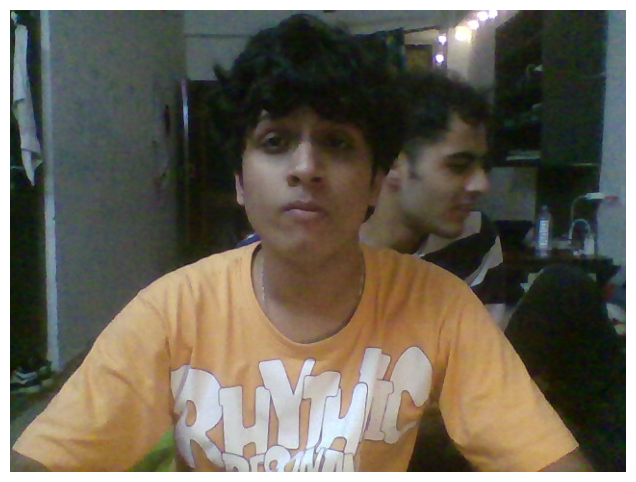

In [12]:
cap = cv2.VideoCapture(0)

ret, frame = cap.read()

cap.release()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(frame_rgb)
    plt.axis("off");
else:
    print("Camera access failed")

In [13]:
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=frame_rgb
)

results = detector.detect(mp_image)

print("Number of faces detected:", len(results.face_landmarks))

Number of faces detected: 1


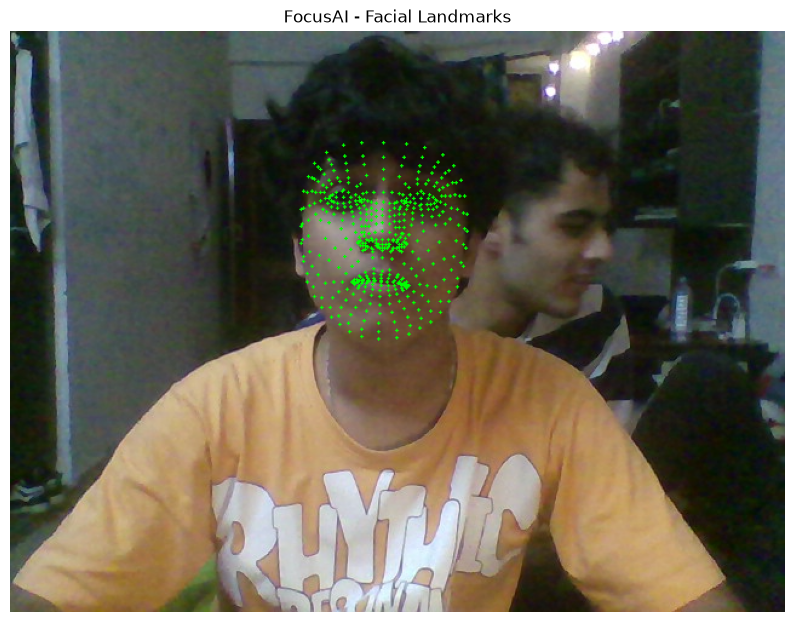

In [14]:
annotated_image = frame_rgb.copy()

if results.face_landmarks:

    for face_landmarks in results.face_landmarks:

        h, w, _ = annotated_image.shape

        for landmark in face_landmarks:

            x = int(landmark.x * w)
            y = int(landmark.y * h)

            cv2.circle(
                annotated_image,
                (x, y),
                1,
                (0, 255, 0),
                -1
            )

plt.figure(figsize=(10, 8))
plt.imshow(annotated_image)
plt.title("FocusAI - Facial Landmarks")
plt.axis("off");

In [10]:
if results.face_landmarks:

    landmarks = results.face_landmarks[0]

    print("Total landmarks:", len(landmarks))

    print("First landmark:")
    print(landmarks[0])

Total landmarks: 478
First landmark:
NormalizedLandmark(x=0.49371713399887085, y=0.4544648230075836, z=-0.03947075456380844, visibility=0.0, presence=0.0)
